# Identifikasi Dataset 1: Klasifikasi Biner
**Dataset:** Indonesian Abusive Language Detection (Twitter) — versi 2 label

## Keterangan dataset
- **Sumber:** GitHub `okkyibrohim/id-abusive-language-detection`, file `re_dataset_two_labels.csv`. Dibuat oleh Muhammad Okky Ibrohim & Indra Budi (Procedia Computer Science 135, 2018). Lisensi CC BY-NC-SA 4.0.
- **Jenis data:** **teks** (tweet berbahasa Indonesia). Username dan URL sudah diganti `USER` dan `URL`.
- **Label:** `1` = bukan abusive, `2` = abusive.
- **Tujuan:** mendeteksi apakah sebuah tweet mengandung bahasa abusive atau tidak.

In [5]:
import os, urllib.request
import pandas as pd

FILE = "re_dataset_two_labels.csv"

if not os.path.exists(FILE):          # unduh sekali, lalu pakai file lokal
    urllib.request.urlretrieve(URL, FILE)

def read_csv_safe(path):
    """Baca CSV dengan mencoba beberapa encoding."""
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("Encoding file tidak dikenali")

df = read_csv_safe(FILE)
print("Kolom:", list(df.columns))
df.head()

Kolom: ['Label', 'Tweet']


,Label,Tweet
0,2,- Dia sendiri yang ngiklanin promo cashback di...
1,2,- disaat semua cowok berusaha melacak perhatia...
2,2,- kampret kan kalo typo-nya di email kantor ke...
3,2,"- Mending makan disini lebih murah, buang-buan..."
4,2,/biarin oppa masukim vibrator ke memek/ oppa k...


## Pisahkan fitur (X) dan label (y)

In [6]:
# kolom teks = kolom bertipe object dengan rata-rata panjang terbesar
text_col = df.select_dtypes("object").apply(lambda s: s.astype(str).str.len().mean()).idxmax()
# kolom label = kolom lain dengan nilai unik sedikit
label_col = [c for c in df.columns if c != text_col and df[c].nunique() <= 3][0]

X = df[text_col]    # data fitur (teks tweet)
y = df[label_col]   # data label

print("Kolom fitur  :", text_col)
print("Kolom label  :", label_col)
print("Jumlah data     :", df.shape[0])
print("Jumlah variabel :", df.shape[1], "(1 fitur teks + 1 label)")
print("Rata-rata panjang teks :", round(X.astype(str).str.len().mean(), 1), "karakter")

Kolom fitur  : Tweet
Kolom label  : Label
Jumlah data     : 2016
Jumlah variabel : 2 (1 fitur teks + 1 label)
Rata-rata panjang teks : 97.4 karakter


C:\Users\Fauzan\AppData\Local\Temp\ipykernel_1124\2121650653.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_col = df.select_dtypes("object").apply(lambda s: s.astype(str).str.len().mean()).idxmax()


In [7]:
df[[text_col, label_col]].sample(5, random_state=1)

,Tweet,Label
351,USER Gw sejak akil baliq 17 tahun Islam.\nDipe...,2
1470,RT USER: USER USER USER USER USER USER USER US...,1
1657,RT USER: mau masak eh malah di ajak ngentot si...,2
703,USER Udah anjir :( udah kerja :( sedih karna i...,2
1975,"tp ini true bgt. Kyuhyun mana ada, di pantai a...",2


In [8]:
df.info()
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2016 entries, 0 to 2015
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Label   2016 non-null   int64
 1   Tweet   2016 non-null   str  
dtypes: int64(1), str(1)
memory usage: 31.6 KB
Label    0
Tweet    0
dtype: int64


Label
2    1685
1     331
Name: count, dtype: int64


<Axes: title={'center': 'Distribusi label'}, xlabel='Label'>

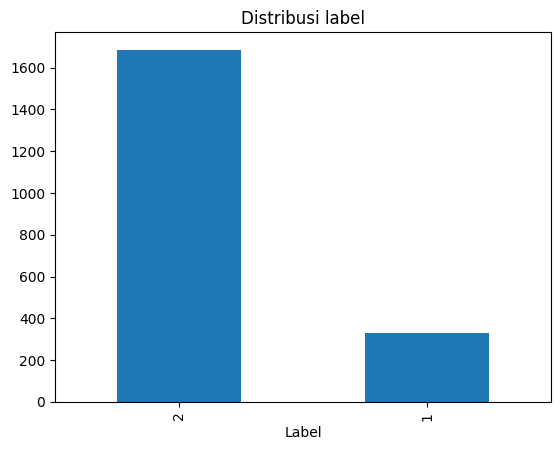

In [9]:
print(y.value_counts())
y.value_counts().plot(kind="bar", title="Distribusi label")

## Kesimpulan jenis klasifikasi

In [10]:
n_kelas = y.nunique()
if n_kelas == 2:
    jenis = "Klasifikasi Biner"
elif n_kelas > 2:
    jenis = "Klasifikasi Multikelas"
print(f"Label '{label_col}' punya {n_kelas} kelas: {sorted(y.unique())}")
print("Kesimpulan:", jenis)

Label 'Label' punya 2 kelas: [np.int64(1), np.int64(2)]
Kesimpulan: Klasifikasi Biner


**Kesimpulan:** Dataset ini **Klasifikasi Biner** pada **data teks**. Hanya ada **1 kolom label** dengan **2 kelas** (bukan abusive vs abusive), dan setiap tweet masuk ke tepat satu kelas.